# **Exercise: Data Preparation**

Pada latihan kali ini, kita akan menggunakan beberapa metode yang telah kita pelajari:

- Encoding
- Scaling
- Regularization
<br><br>

**Gunakan melb_data.csv (Melbourne House Data) dengan:**
- Features: 'Suburb', 'Rooms', 'Type', 'Method', 'Distance', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Regionname'
- Target: 'Price'

**Lakukan tahapan ini pada preprocessing dan modeling:**
- Lakukan EDA secara sederhana untuk eksplorasi dataset.
- Splitting dataset dengan proporsi 80:20 dan random_state = 2020
- Gunakan ColumnTransformer untuk encoding.
    - Ada 5 features categorical. Lakukan encoding pada features tersebut sesuai dengan karakter masing-masing feature.
- Lakukan Scaling pada numerical features. Pilih scaler yang menurut kamu paling sesuai berdasarkan karakteristik datanya.
- Lakukan fitting model dan evaluasi dengan metode Lasso pada data yang telah dilakukan preprocessing.

Keterangan features:
https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot

## **Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## **Load & Explore Dataset**

In [2]:
pd.set_option('display.max_columns', 100)

In [4]:
df = pd.read_csv('melb_data.csv')
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [5]:
df = df[['Suburb','Rooms','Type','Method','Distance','Bedroom2','Bathroom','Car','Landsize',
            'BuildingArea','YearBuilt','CouncilArea','Regionname','Price']]

In [6]:
df.shape

(13580, 14)

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Rooms,13580.0,2.937997e+00,0.955748,1.0,2.0,3.0,3.0,10.0
Distance,13580.0,1.013778e+01,5.868725,0.0,6.1,9.2,13.0,48.1
Bedroom2,13580.0,2.914728e+00,0.965921,0.0,2.0,3.0,3.0,20.0
Bathroom,13580.0,1.534242e+00,0.691712,0.0,1.0,1.0,2.0,8.0
Car,13518.0,1.610075e+00,0.962634,0.0,1.0,2.0,2.0,10.0
Landsize,13580.0,5.584161e+02,3990.669241,0.0,177.0,440.0,651.0,433014.0
BuildingArea,7130.0,1.519676e+02,541.014538,0.0,93.0,126.0,174.0,44515.0
YearBuilt,8205.0,1.964684e+03,37.273762,1196.0,1940.0,1970.0,1999.0,2018.0
Price,13580.0,1.075684e+06,639310.724296,85000.0,650000.0,903000.0,1330000.0,9000000.0


In [8]:
df.describe(include='object')

,Suburb,Type,Method,CouncilArea,Regionname
count,13580,13580,13580,12211,13580
unique,314,3,5,33,8
top,Reservoir,h,S,Moreland,Southern Metropolitan
freq,359,9449,9022,1163,4695


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Suburb        13580 non-null  object 
 1   Rooms         13580 non-null  int64  
 2   Type          13580 non-null  object 
 3   Method        13580 non-null  object 
 4   Distance      13580 non-null  float64
 5   Bedroom2      13580 non-null  float64
 6   Bathroom      13580 non-null  float64
 7   Car           13518 non-null  float64
 8   Landsize      13580 non-null  float64
 9   BuildingArea  7130 non-null   float64
 10  YearBuilt     8205 non-null   float64
 11  CouncilArea   12211 non-null  object 
 12  Regionname    13580 non-null  object 
 13  Price         13580 non-null  float64
dtypes: float64(8), int64(1), object(5)
memory usage: 1.5+ MB


In [10]:
df.select_dtypes('object').head()

,Suburb,Type,Method,CouncilArea,Regionname
0,Abbotsford,h,S,Yarra,Northern Metropolitan
1,Abbotsford,h,S,Yarra,Northern Metropolitan
2,Abbotsford,h,SP,Yarra,Northern Metropolitan
3,Abbotsford,h,PI,Yarra,Northern Metropolitan
4,Abbotsford,h,VB,Yarra,Northern Metropolitan


### **Simple EDA**

In [11]:
# categorical features
cat_features = [feature for feature in df.columns if ((df[feature].dtypes == 'O') & (feature not in ['Suburb']))]
cat_features

['Type', 'Method', 'CouncilArea', 'Regionname']

In [12]:
# list(df.describe(include='object'))

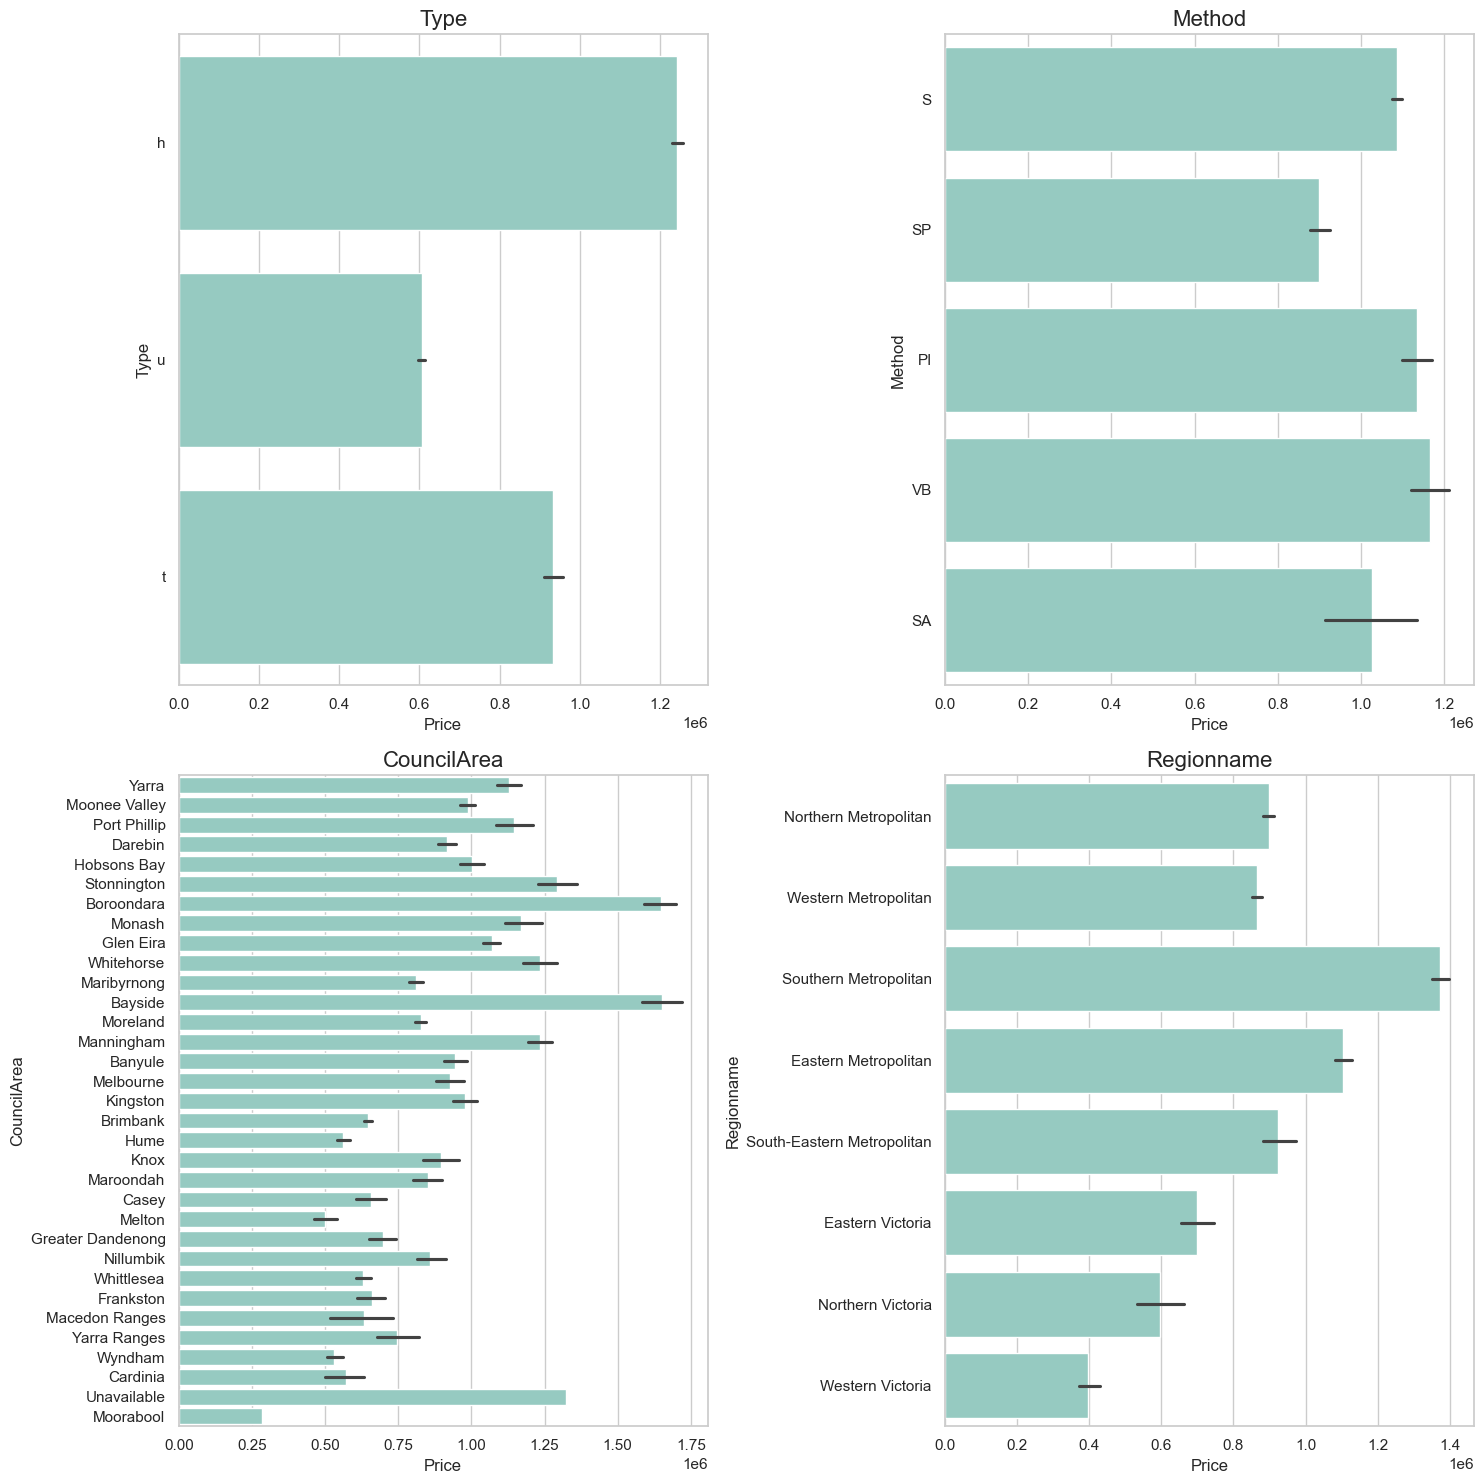

In [13]:
# Harga rumah berdasarkan tiap categorical feature

plt.figure(figsize=(15, 15), facecolor='white')
sns.set(style='whitegrid', palette='Set3')
plotnumber = 1

for feature in cat_features:
    # subplot (letak grafik)
    ax = plt.subplot(2, 2, plotnumber)
    
    # Harga rumah berdasarkan feature 
    sns.barplot(x = 'Price', y = feature, data = df)
    
    plt.xlabel('Price')
    plt.ylabel(feature)
    plt.title(feature, fontsize=16)
    plt.tight_layout();
    
    plotnumber += 1

<Axes: ylabel='Price'>

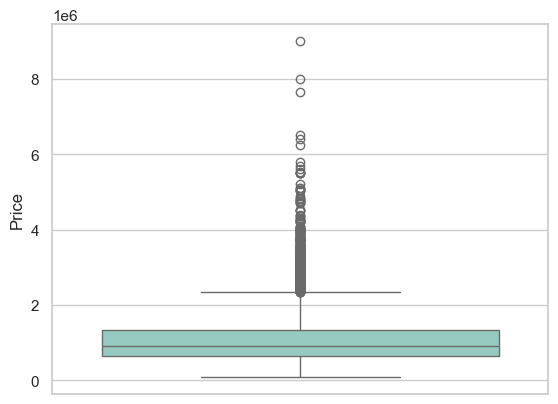

In [17]:
# Distribusi Harga Rumah
sns.boxplot(data=df,y='Price')

In [18]:
# Numerical Features
num_feature = [fea for fea in df.describe().columns]
num_feature

['Rooms',
 'Distance',
 'Bedroom2',
 'Bathroom',
 'Car',
 'Landsize',
 'BuildingArea',
 'YearBuilt',
 'Price']

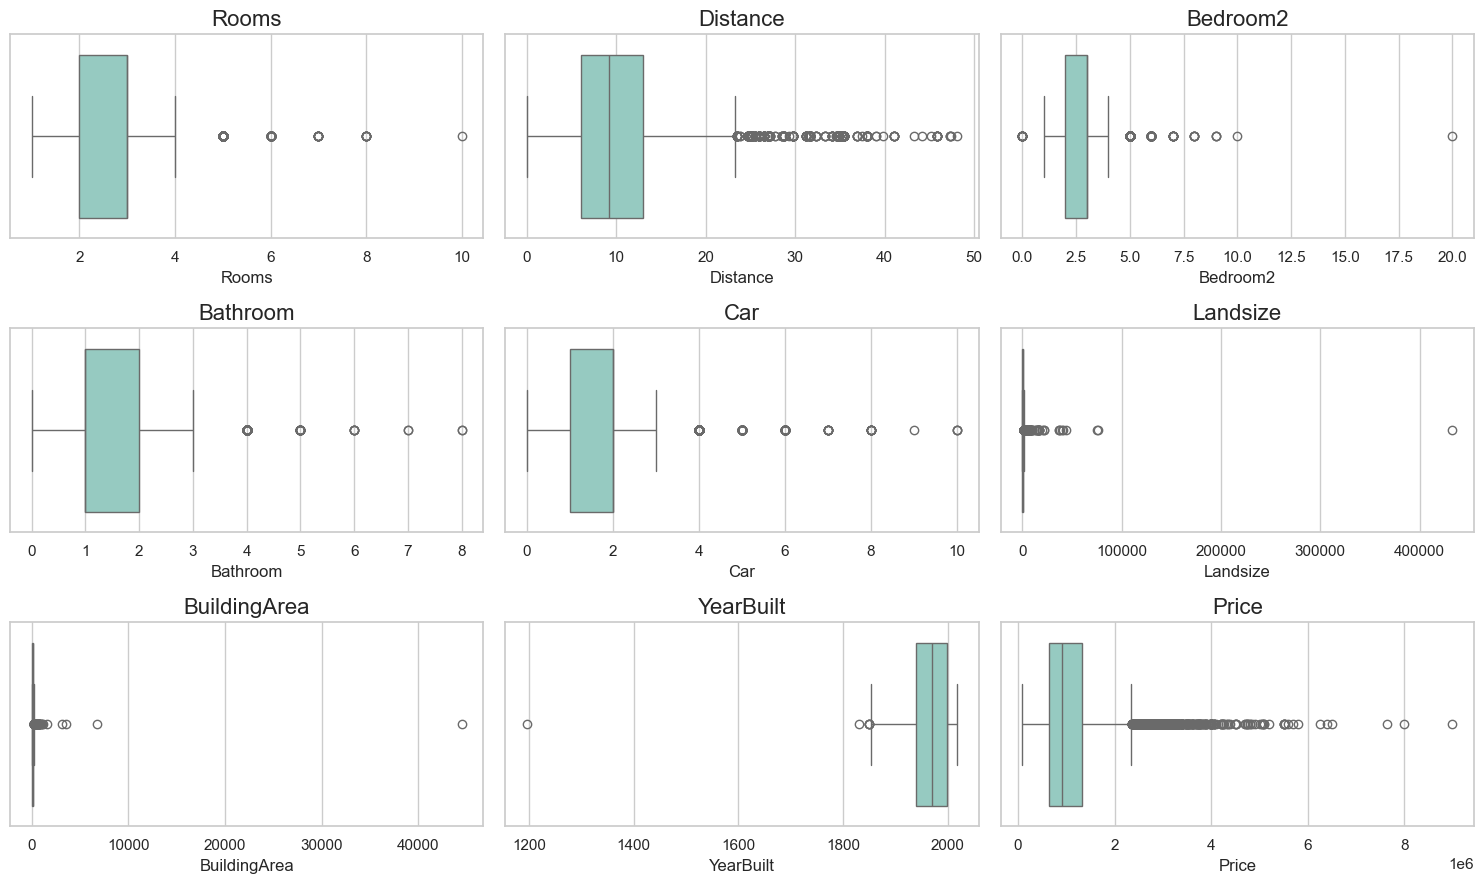

In [19]:
plt.figure(figsize=(15, 9), facecolor='white')
sns.set(style='whitegrid', palette='Set3')
plotnumber = 1
    
for feature in num_feature:
    ax = plt.subplot(3,3, plotnumber)
    sns.boxplot(x=feature, data=df);
    plt.title(feature, fontsize=16)
    plt.tight_layout()
    plotnumber += 1


In [20]:
# Outliers
outliers = df[((df['Bedroom2'] > 10) | (df['Landsize'] > 100000) | (df['BuildingArea'] > 10000) | (df['YearBuilt'] < 1800)) ]
outliers

,Suburb,Rooms,Type,Method,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,Price
7404,Caulfield East,3,h,PI,9.3,20.0,1.0,2.0,875.0,NaN,NaN,Glen Eira,Southern Metropolitan,1650000.0
9968,Mount Waverley,3,h,VB,14.2,3.0,1.0,4.0,807.0,117.0,1196.0,Monash,Eastern Metropolitan,1200000.0
11020,Fitzroy,3,h,VB,2.1,3.0,3.0,1.0,433014.0,NaN,NaN,Yarra,Northern Metropolitan,2700000.0
13245,New Gisborne,5,h,S,48.1,5.0,3.0,5.0,44500.0,44515.0,NaN,NaN,Northern Victoria,1355000.0


In [21]:
# df = df.drop(outliers.index, axis=0)

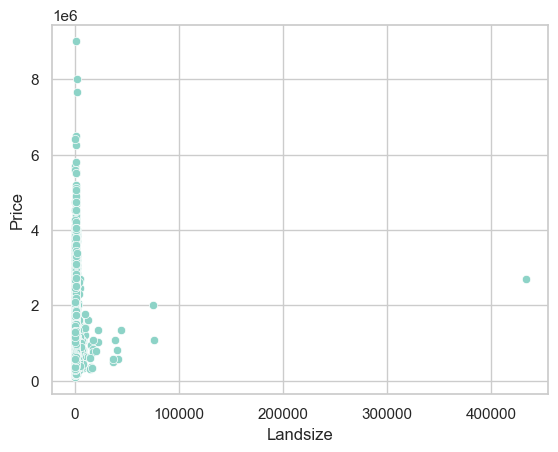

In [22]:
# Price vs Landsize
sns.scatterplot(x='Landsize', y='Price', data=df);

In [23]:
# Outlier pada Landsize
df[df['Landsize'] > 400000]

,Suburb,Rooms,Type,Method,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,Price
11020,Fitzroy,3,h,VB,2.1,3.0,3.0,1.0,433014.0,NaN,NaN,Yarra,Northern Metropolitan,2700000.0


In [25]:
df

,Suburb,Rooms,Type,Method,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,Price
0,Abbotsford,2,h,S,2.5,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,Northern Metropolitan,1480000.0
1,Abbotsford,2,h,S,2.5,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,Northern Metropolitan,1035000.0
2,Abbotsford,3,h,SP,2.5,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,Northern Metropolitan,1465000.0
3,Abbotsford,3,h,PI,2.5,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,Northern Metropolitan,850000.0
4,Abbotsford,4,h,VB,2.5,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,Northern Metropolitan,1600000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13575,Wheelers Hill,4,h,S,16.7,4.0,2.0,2.0,652.0,NaN,1981.0,NaN,South-Eastern Metropolitan,1245000.0
13576,Williamstown,3,h,SP,6.8,3.0,2.0,2.0,333.0,133.0,1995.0,NaN,Western Metropolitan,1031000.0
13577,Williamstown,3,h,S,6.8,3.0,2.0,4.0,436.0,NaN,1997.0,NaN,Western Metropolitan,1170000.0
13578,Williamstown,4,h,PI,6.8,4.0,1.0,5.0,866.0,157.0,1920.0,NaN,Western Metropolitan,2500000.0


In [26]:
df[['Rooms','Distance','Bedroom2','Car','Landsize','BuildingArea','YearBuilt','Price']].corr()

,Rooms,Distance,Bedroom2,Car,Landsize,BuildingArea,YearBuilt,Price
Rooms,1.000000,0.294203,0.944190,0.408483,0.025678,0.124127,-0.065413,0.496634
Distance,0.294203,1.000000,0.295927,0.262994,0.025004,0.099481,0.246379,-0.162522
Bedroom2,0.944190,0.295927,1.000000,0.405325,0.025646,0.122319,-0.053319,0.475951
Car,0.408483,0.262994,0.405325,1.000000,0.026770,0.096101,0.104515,0.238979
Landsize,0.025678,0.025004,0.025646,0.026770,1.000000,0.500485,0.036451,0.037507
BuildingArea,0.124127,0.099481,0.122319,0.096101,0.500485,1.000000,0.019665,0.090981
YearBuilt,-0.065413,0.246379,-0.053319,0.104515,0.036451,0.019665,1.000000,-0.323617
Price,0.496634,-0.162522,0.475951,0.238979,0.037507,0.090981,-0.323617,1.000000


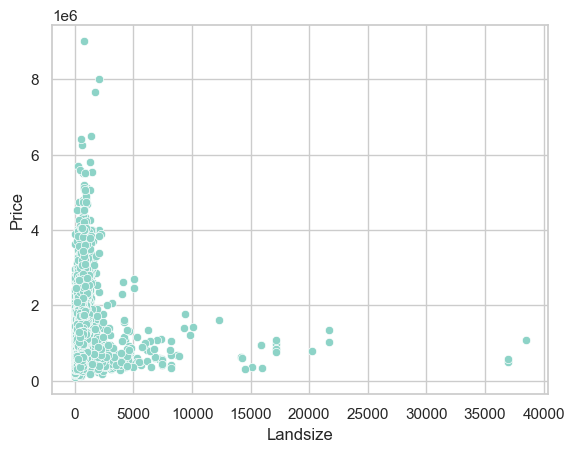

In [27]:
sns.scatterplot(x='Landsize', y='Price', data=df[df['Landsize'] < 40000]);

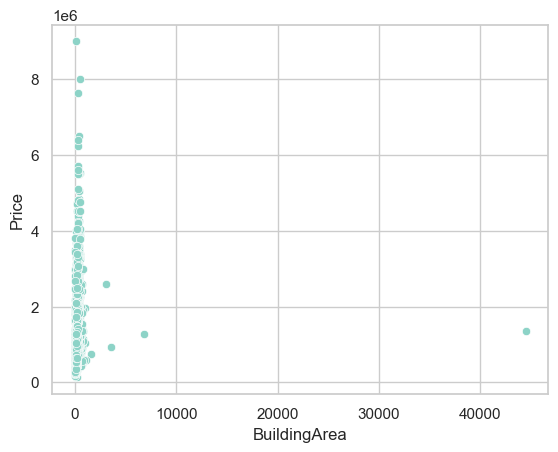

In [28]:
# Building Area vs Price
sns.scatterplot(x='BuildingArea', y='Price', data=df);

In [29]:
# Outlier
df[df['BuildingArea'] > 40000]

,Suburb,Rooms,Type,Method,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,Price
13245,New Gisborne,5,h,S,48.1,5.0,3.0,5.0,44500.0,44515.0,NaN,NaN,Northern Victoria,1355000.0


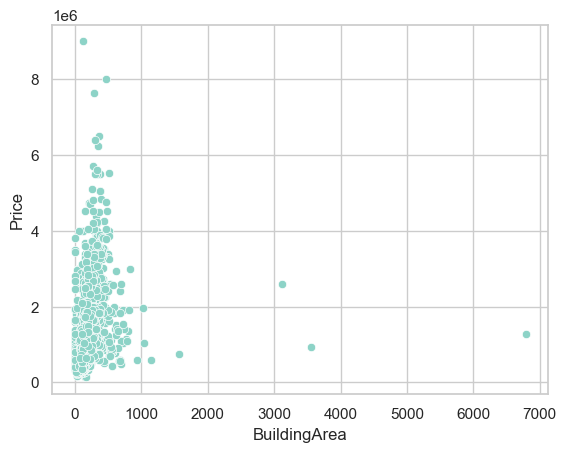

In [30]:
sns.scatterplot(x='BuildingArea', y='Price', data=df[df['BuildingArea'] < 20000]);

In [31]:
df.isna().sum()

Suburb             0
Rooms              0
Type               0
Method             0
Distance           0
Bedroom2           0
Bathroom           0
Car               62
Landsize           0
BuildingArea    6450
YearBuilt       5375
CouncilArea     1369
Regionname         0
Price              0
dtype: int64

In [42]:
# Check correlation to the target
df[['Rooms','Distance','Bedroom2','Car','Landsize','BuildingArea','YearBuilt','Price']].corr().loc['Price']


Rooms           0.496634
Distance       -0.162522
Bedroom2        0.475951
Car             0.238979
Landsize        0.037507
BuildingArea    0.090981
YearBuilt      -0.323617
Price           1.000000
Name: Price, dtype: float64

## **Load Data**

In [ ]:
# !pip install category_encoders

In [43]:
# Import Libraries
from sklearn.experimental import enable_iterative_imputer 
from sklearn.impute import IterativeImputer
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer # untuk transformers
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import category_encoders as ce # untuk ordinal dan binary encoder
from sklearn.preprocessing import RobustScaler

In [44]:
df = pd.read_csv('melb_data.csv')
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [45]:
# Outliers
outliers = df[((df['Bedroom2'] > 10) | (df['Landsize'] > 100000) | (df['BuildingArea'] > 10000) | (df['YearBuilt'] < 1800)) ]
outliers

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
7404,Caulfield East,5 Grange Rd,3,h,1650000.0,PI,Woodards,6/08/2016,9.3,3145.0,20.0,1.0,2.0,875.0,NaN,NaN,Glen Eira,-37.88150,145.04910,Southern Metropolitan,608.0
9968,Mount Waverley,5 Armstrong St,3,h,1200000.0,VB,McGrath,24/06/2017,14.2,3149.0,3.0,1.0,4.0,807.0,117.0,1196.0,Monash,-37.86788,145.12121,Eastern Metropolitan,13366.0
11020,Fitzroy,389 Gore St,3,h,2700000.0,VB,Kay,12/08/2017,2.1,3065.0,3.0,3.0,1.0,433014.0,NaN,NaN,Yarra,-37.79751,144.98309,Northern Metropolitan,5825.0
13245,New Gisborne,71 Hamilton Rd,5,h,1355000.0,S,Raine,23/09/2017,48.1,3438.0,5.0,3.0,5.0,44500.0,44515.0,NaN,NaN,-37.45392,144.58864,Northern Victoria,849.0


In [46]:
# drop outliers
df = df.drop(outliers.index, axis=0)

In [47]:
# drop missing values
df.dropna(inplace=True)

In [48]:
df.isna().sum()

Suburb           0
Address          0
Rooms            0
Type             0
Price            0
Method           0
SellerG          0
Date             0
Distance         0
Postcode         0
Bedroom2         0
Bathroom         0
Car              0
Landsize         0
BuildingArea     0
YearBuilt        0
CouncilArea      0
Lattitude        0
Longtitude       0
Regionname       0
Propertycount    0
dtype: int64

## **Data Splitting**

In [49]:
# Define X and y
X = df[['Suburb', 'Rooms', 'Type', 'Method', 'Distance', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Regionname']]
y = df['Price']

In [50]:
# Splitting
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size=0.2,
    random_state=2020
)

## **Data Transform**

### Encoding:
- Binary Encoding : 'Suburb', 'CouncilArea', 'Regionname'
- Onehot Encoding : 'Type', 'Method'

### Scaling:
- RobustScaler() karena terdapat banyak outliers

In [51]:
df.describe(include='object')

,Suburb,Address,Type,Method,SellerG,Date,CouncilArea,Regionname
count,6195,6195,6195,6195,6195,6195,6195,6195
unique,287,6116,3,5,203,51,31,8
top,Reservoir,36 Aberfeldie St,h,S,Nelson,27/05/2017,Moreland,Southern Metropolitan
freq,154,3,4087,3957,763,225,658,2166


In [52]:
# Encoding
transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(), ['Type','Method']),
    ('binary', ce.BinaryEncoder(), ['Suburb','CouncilArea','Regionname']),
], remainder='passthrough')

In [53]:
# .fit and .transform method
X_train_prep = transformer.fit_transform(X_train) 

# .transform method
X_test_prep = transformer.transform(X_test) 

## **Scaling**

In [54]:
# Scaling
scaler = RobustScaler()

X_train_prep_scaled = scaler.fit_transform(X_train_prep)
X_test_prep_scaled = scaler.transform(X_test_prep)

In [55]:
X_train_prep_scaled = pd.DataFrame(X_train_prep_scaled)
X_test_prep_scaled = pd.DataFrame(X_test_prep_scaled)

X_train_prep_scaled.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33
0,-1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-1.0,-1.0,1.0,0.0,0.0,-1.0,0.0,-1.0,-0.953846,-2.0,0.0,1.0,-0.783613,-0.265403,-0.083333
1,-1.0,0.0,1.0,0.0,-1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,-1.0,0.0,0.0,0.0,0.0,-1.0,0.0,-0.5,-1.138462,-1.0,0.0,0.0,-0.783613,-0.404423,-1.166667
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,-1.0,0.0,1.0,0.0,0.0,0.0,-1.0,0.0,0.753846,1.0,1.0,1.0,0.455882,-0.063191,-0.166667
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,0.0,0.0,0.0,-0.5,-0.307692,-1.0,0.0,2.0,0.331933,-0.151659,-0.500000
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,-1.0,1.0,0.0,0.0,-1.0,0.0,0.0,0.338462,0.0,0.0,1.0,0.453782,0.063191,-0.333333


In [57]:
# menyatukan nama-nama features

features = list(transformer.transformers_[0][1].get_feature_names_out()) + list(transformer.transformers_[1][1].get_feature_names_out()) + list(X_train.columns[transformer.transformers_[2][2]])

X_train_prep_scaled.columns = features
X_test_prep_scaled.columns = features

X_test_prep_scaled

,Type_h,Type_t,Type_u,Method_PI,Method_S,Method_SA,Method_SP,Method_VB,Suburb_0,Suburb_1,Suburb_2,Suburb_3,Suburb_4,Suburb_5,Suburb_6,Suburb_7,Suburb_8,CouncilArea_0,CouncilArea_1,CouncilArea_2,CouncilArea_3,CouncilArea_4,Regionname_0,Regionname_1,Regionname_2,Regionname_3,Rooms,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt
0,-1.0,0.0,1.0,0.0,-1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.5,-0.153846,-1.0,0.0,0.0,-0.783613,-0.695103,0.000000
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,-1.0,0.0,0.0,1.0,-1.0,0.0,0.0,1.184615,0.0,1.0,1.0,0.577731,0.733017,0.166667
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0,-0.676923,0.0,0.0,0.0,-0.365546,-0.252765,-1.333333
3,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,-1.0,-1.0,0.0,0.0,0.0,0.0,-1.0,0.5,0.338462,1.0,1.0,1.0,-0.182773,2.022117,0.483333
4,-1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,0.0,0.0,-1.0,0.0,-0.5,-1.015385,-1.0,1.0,0.0,-0.783613,-0.606635,0.616667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1234,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.5,0.415385,1.0,1.0,0.0,1.151261,0.644550,-0.333333
1235,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.876923,0.0,1.0,1.0,0.598739,0.025276,0.233333
1236,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1.0,0.0,-0.676923,0.0,0.0,0.0,-0.065126,0.088468,-1.166667
1237,0.0,0.0,0.0,0.0,-1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,-1.0,0.0,0.0,0.0,0.0,-1.0,0.0,-0.5,-0.846154,-1.0,1.0,0.0,-0.502101,0.353870,-1.083333


## **Find the best alpha**


In [58]:
# Import Libraries
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error

In [59]:
# Lasso

alpha = [100000, 10000, 1000, 100, 10, 1, 0.1, 0.01, 0.001, 0.0000001]
training_rmse = []
testing_rmse = []

score = 0

for i in range(len(alpha)):
    lasso = Lasso(alpha=alpha[i])
    lasso.fit(X_train_prep_scaled, y_train)
    
    y_predict_train = lasso.predict(X_train_prep_scaled)
    rmse_train = mean_squared_error(y_train, y_predict_train)**0.5
    training_rmse.append(rmse_train)
    
    y_predict_test = lasso.predict(X_test_prep_scaled)
    rmse_score = mean_squared_error(y_test, y_predict_test)**0.5
    testing_rmse.append(rmse_score)
    
    if i==0:
        score = rmse_score
        best_alpha = alpha[i]
        
    if score > rmse_score:
        score = rmse_score
        best_alpha = alpha[i]

In [60]:
print('Best alpha', best_alpha)
print('RMSE', score)

print('Training RMSE:', training_rmse)
print('Testing RMSE:', testing_rmse)


Best alpha 1000
RMSE 357615.06071613374
Training RMSE: [535315.0378206494, 420290.9482221532, 409653.4966559922, 409273.6860188308, 409263.18760422705, 409263.0817959122, 409263.0807210158, 409263.08071035007, 409263.08071024343, 409263.0807102424]
Testing RMSE: [488435.345022467, 367971.2481786985, 357615.06071613374, 358059.12840605894, 358129.3139374593, 358136.2767688132, 358136.99268568435, 358137.0752198413, 358137.08347498026, 358137.08439214557]


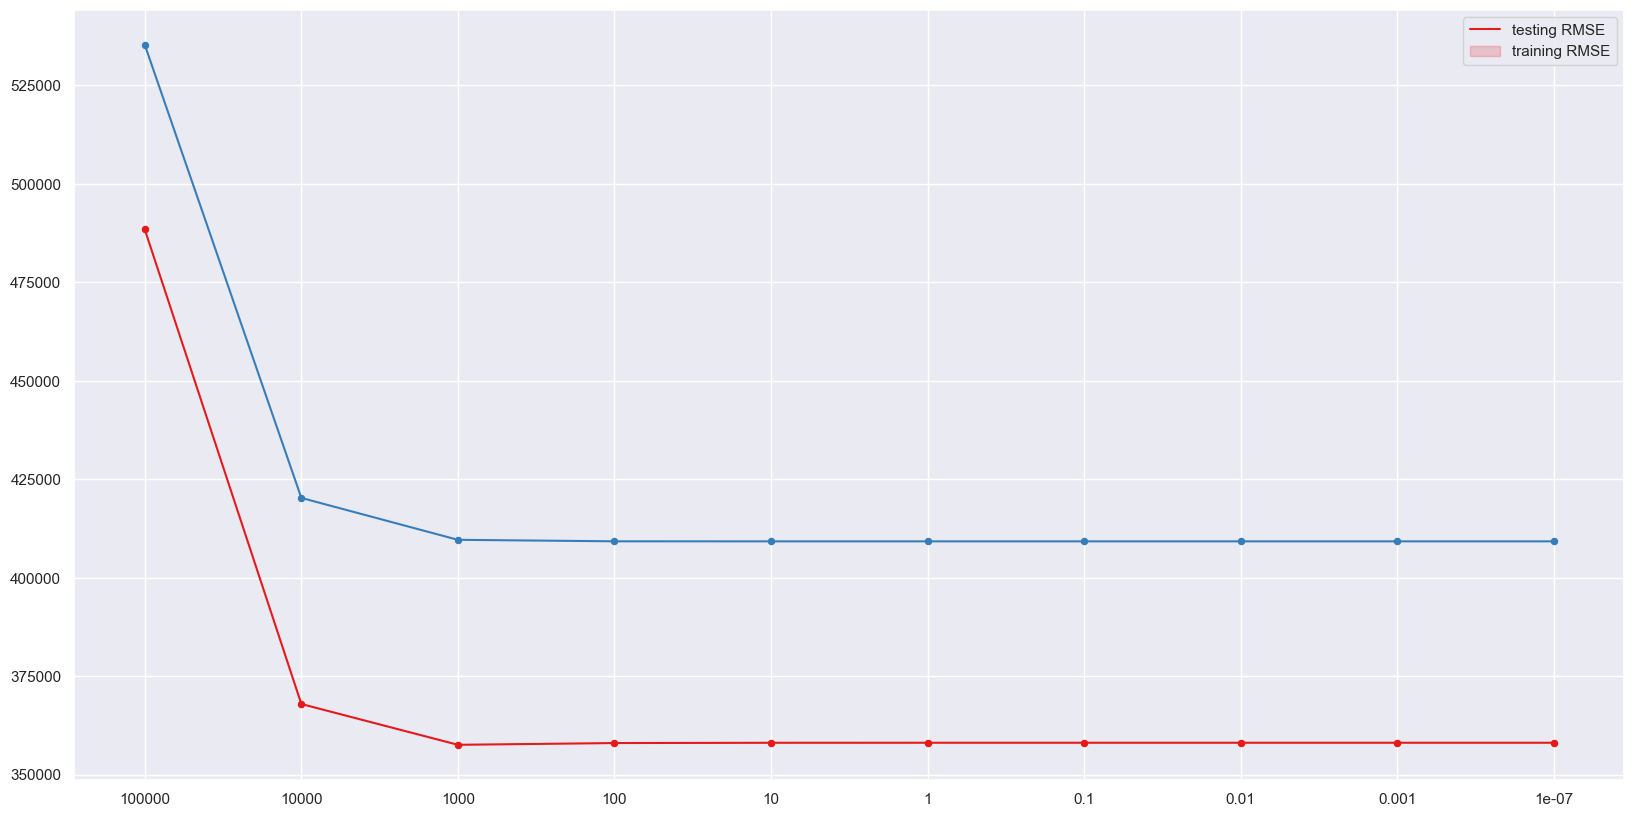

In [61]:
# Plot the alphas
sns.set(palette='Set1')
length = range(len(alpha))

plt.figure(figsize = (20,10))

sns.lineplot(x=length, y=testing_rmse)
sns.scatterplot(x=length, y=testing_rmse)

sns.lineplot(x=length,y=training_rmse)
sns.scatterplot(x=length, y=training_rmse)

plt.legend(['testing RMSE', 'training RMSE'])
plt.xticks(length, alpha);

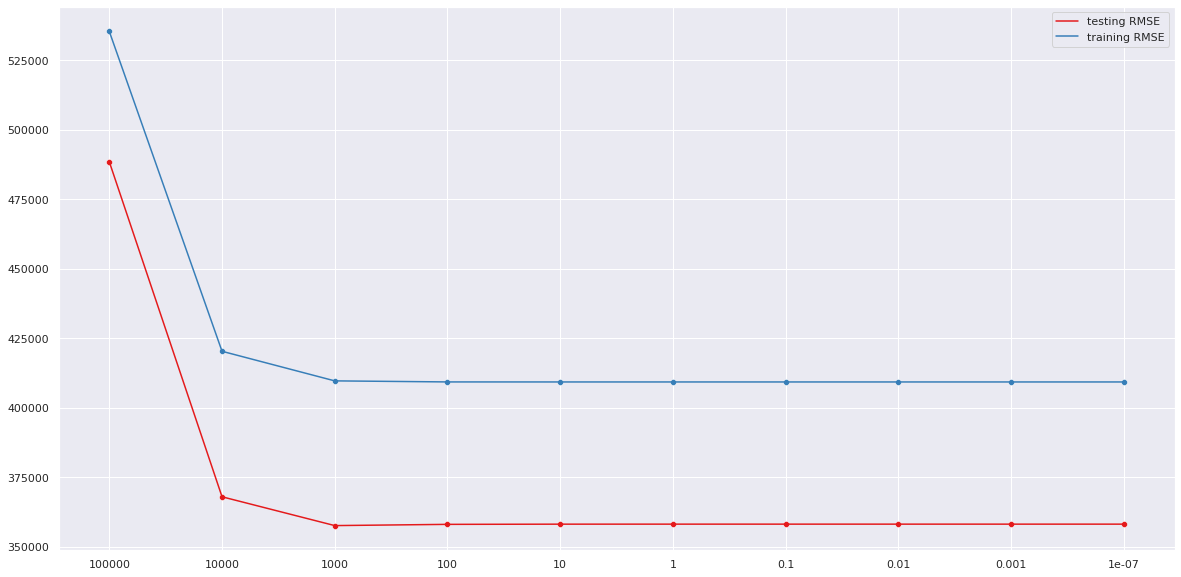

In [ ]:
# # Plot the alphas
# sns.set(palette='Set1')
# length = range(len(alpha))

# plt.figure(figsize = (20,10))

# sns.lineplot(length, testing_rmse)
# sns.scatterplot(length, testing_rmse)

# sns.lineplot(length,training_rmse)
# sns.scatterplot(length, training_rmse)

# plt.legend(['testing RMSE', 'training RMSE'])
# plt.xticks(length, alpha);

In [62]:
pd.DataFrame(
    {
    'alpha': alpha,
    'train RMSE': training_rmse,
    'test RMSE': testing_rmse
    }
)

,alpha,train RMSE,test RMSE
0,1.000000e+05,535315.037821,488435.345022
1,1.000000e+04,420290.948222,367971.248179
2,1.000000e+03,409653.496656,357615.060716
3,1.000000e+02,409273.686019,358059.128406
4,1.000000e+01,409263.187604,358129.313937
5,1.000000e+00,409263.081796,358136.276769
6,1.000000e-01,409263.080721,358136.992686
7,1.000000e-02,409263.080710,358137.075220
8,1.000000e-03,409263.080710,358137.083475
9,1.000000e-07,409263.080710,358137.084392


### **Interpretasi**

Dari alpha 1 sampai 0.00001, nilai RMSE untuk train dan test set sudah tidak terlalu berubah signifikan. Jadi, untuk kasus kali ini, kita bisa menggunakan alpha=1000.

## **Modeling**

In [63]:
# Model
model = Lasso(alpha=1000)

# Model training
model.fit(X_train_prep_scaled, y_train)

# Model predicting test set  
y_pred = model.predict(X_test_prep_scaled)

# Metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print('MSE:', mse)
print('RMSE:', rmse)

MSE: 127888531651.00403
RMSE: 357615.06071613374


### **Model Properties**

In [64]:
model_coef = pd.DataFrame({
    'feature': list(X_train_prep_scaled),
    'coef': model.coef_
}).sort_values('coef')

model_coef

,feature,coef
25,Regionname_3,-454208.129893
27,Distance,-252846.219892
33,YearBuilt,-176692.068969
2,Type_u,-161785.027197
17,CouncilArea_0,-114895.886420
21,CouncilArea_4,-89830.038439
24,Regionname_2,-63864.057356
12,Suburb_4,-35184.217169
14,Suburb_6,-33740.378137
3,Method_PI,-16027.119738


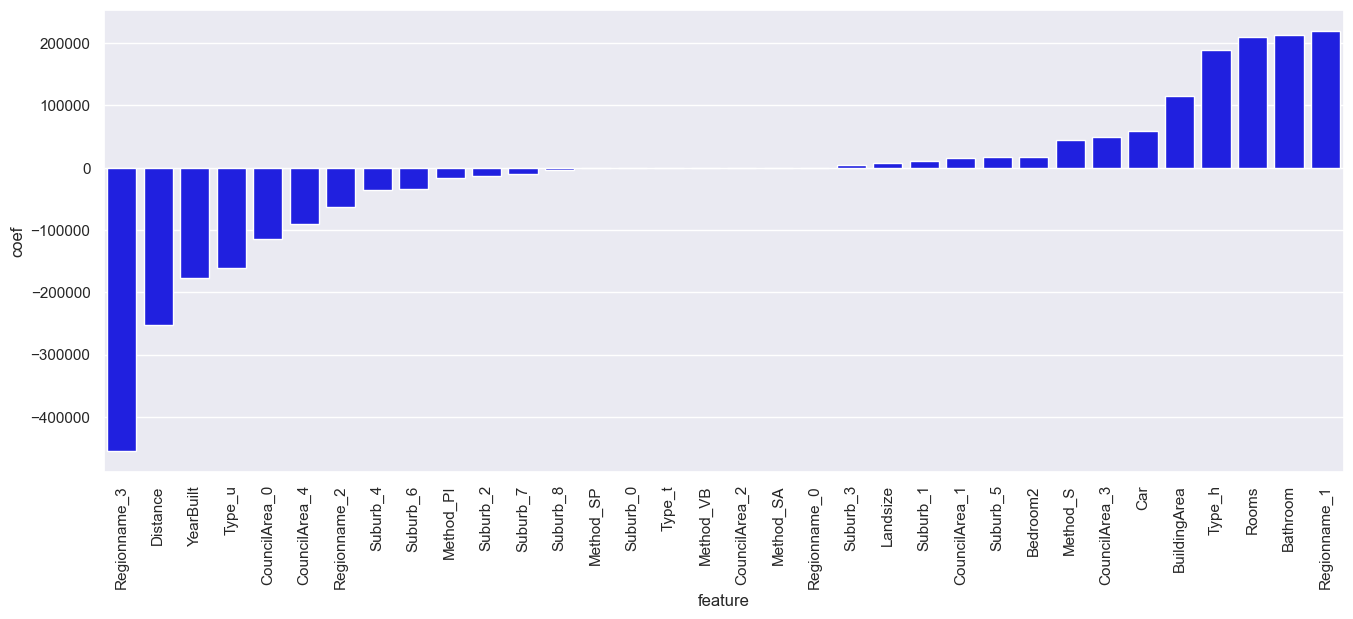

In [65]:
plt.figure(figsize=(16,6))
sns.barplot(data=model_coef, x='feature', y='coef', color='b')
plt.xticks(rotation=90)
plt.show()

## Kesimpulan

1. Feature yang penting untuk model kita adalah:

    Slope positive:
    - Bathroom (makin banyak bathroom, maka semakin mahal harga rumahnya)
    - Rooms (makin banyak room, maka semakin mahal harga rumahnya)
    - BuildingArea (makin luas Building Area, maka semakin mahal harga rumahnya)

 Slope Negative:
    - x0_u (tipe rumah unit) (Kalau rumahnya type unit, harganya cenderung lebih murah dari pada tipe rumah lain)
    - Distance (semakin dekat jarak ke kota, maka semakin mahal harga rumahnya)
    - YearBuilt (semakin tua sebuah rumah (angka tahunnya kecil), maka semakin mahal harga rumahnya)


 2. Drop outliers dapat meningkatkan performa model